# Mecânica Estocástica Computacional
## Exercícios computacionais

Luca Ainstein

In [1]:
from pathlib import Path
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import StrMethodFormatter

%matplotlib inline
%config InlineBackend.figure_format = "retina"

verde = "#207451"
verde_escuro = "#164B36"
salvar_figuras = False

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.labelcolor": "#25352D",
    "axes.edgecolor": "#A1ADA6",
    "axes.titlecolor": verde_escuro,
    "font.size": 10,
    "xtick.color": "#3C4A43",
    "ytick.color": "#3C4A43",
    "grid.color": "#DCE5DF",
    "grid.linewidth": 0.7,
    "axes.axisbelow": True,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "legend.frameon": False,
})


def mostrar_figura(figura, nome):
    if salvar_figuras:
        pasta = Path("figuras")
        pasta.mkdir(exist_ok=True)
        figura.savefig(pasta / nome, dpi=220, bbox_inches="tight")
    plt.show()

## Exercício 1 — Transformada inversa

Gere $10^3$ e $10^5$ realizações da densidade $p_X(x)=2x$, para $0\leq x\leq1$, e compare os histogramas normalizados com a densidade teórica. Como $F_X(x)=x^2$ no suporte, use $X=\sqrt{U}$ com $U$ uniforme em $[0,1]$.

In [2]:
rng_inversa = np.random.default_rng(7107)
tamanhos_inversa = (1_000, 100_000)
x_inversa = np.sqrt(rng_inversa.random(max(tamanhos_inversa)))
bins_inversa = np.linspace(0, 1, 21)
densidade_media_inversa = np.diff(bins_inversa**2) / np.diff(bins_inversa)

print(f"Média teórica = {2 / 3:.6f}")
print(f"{'n':>8} {'média':>10} {'erro RMS do histograma':>24}")
for n in tamanhos_inversa:
    amostra = x_inversa[:n]
    hist, _ = np.histogram(amostra, bins=bins_inversa, density=True)
    erro_rms = np.sqrt(np.mean((hist - densidade_media_inversa)**2))
    print(f"{n:8d} {amostra.mean():10.6f} {erro_rms:24.6f}")

Média teórica = 0.666667
       n      média   erro RMS do histograma
    1000   0.656873                 0.221585
  100000   0.666306                 0.011307


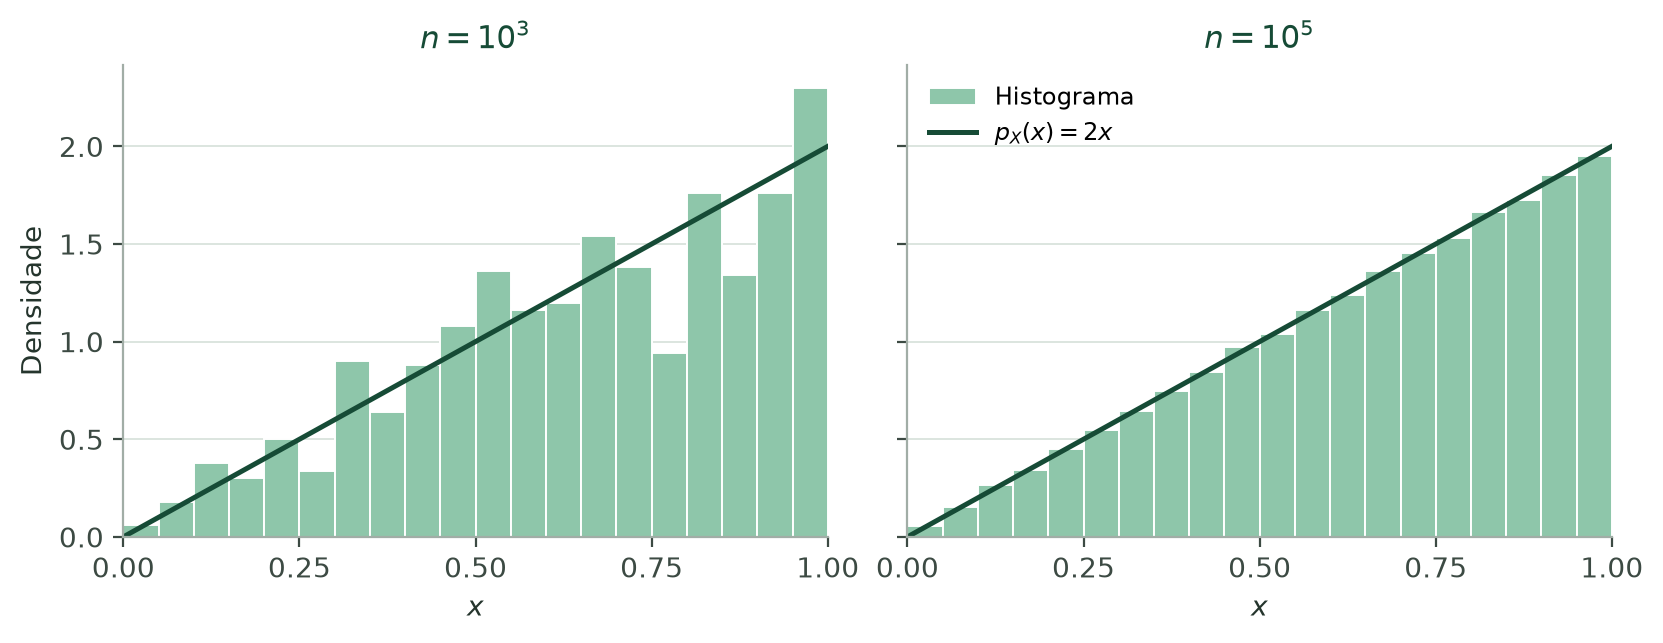

In [3]:
fig, eixos = plt.subplots(1, 2, figsize=(8.2, 3.1), sharex=True, sharey=True,
                         layout="constrained")
x_teorico = np.linspace(0, 1, 200)
for eixo, n, titulo in zip(eixos, tamanhos_inversa, ("$n=10^3$", "$n=10^5$")):
    eixo.hist(x_inversa[:n], bins=bins_inversa, density=True, color="#8EC6AA",
              edgecolor="white", linewidth=0.7, label="Histograma")
    eixo.plot(x_teorico, 2 * x_teorico, color=verde_escuro, linewidth=1.8,
              label=r"$p_X(x)=2x$")
    eixo.set(title=titulo, xlabel="$x$", xlim=(0, 1))
    eixo.set_xticks(np.linspace(0, 1, 5))
    eixo.grid(axis="y")
eixos[0].set_ylabel("Densidade")
eixos[0].set_ylim(bottom=0)
eixos[1].legend(loc="upper left", fontsize=8.5)
mostrar_figura(fig, "transformada_inversa.png")

## Exercício 2 — Método da rejeição

Gere $10^4$ e $2\times10^5$ realizações aceitas de uma densidade proporcional a $e^{-x_1-x_2}$ no quadrado unitário. Para uma proposta uniforme $Y$ no quadrado, aceite-a se $U \leq e^{-Y_1-Y_2}$, com $U$ uniforme e independente de $Y$. Compare as densidades e as taxas de aceitação.

In [4]:
def gerar_por_rejeicao(n, rng):
    aceitas = np.empty((n, 2))
    total_aceitas = 0
    total_propostas = 0

    while total_aceitas < n:
        propostas = rng.random((16_384, 3))
        pontos = propostas[:, :2]
        indices = np.flatnonzero(propostas[:, 2] <= np.exp(-pontos.sum(axis=1)))
        indices = indices[:n - total_aceitas]
        fim = total_aceitas + len(indices)
        aceitas[total_aceitas:fim] = pontos[indices]
        total_propostas += indices[-1] + 1 if fim == n else len(pontos)
        total_aceitas = fim

    return aceitas, total_propostas


rng_rejeicao = np.random.default_rng(8208)
tamanhos_rejeicao = (10_000, 200_000)
bins_rejeicao = np.linspace(0, 1, 26)
normalizacao = 1 - np.exp(-1)
aceitacao_teorica = normalizacao**2
media_teorica_rejeicao = (1 - 2 * np.exp(-1)) / normalizacao
marginal_media = -np.diff(np.exp(-bins_rejeicao)) / (
    normalizacao * np.diff(bins_rejeicao)
)
densidade_teorica_rejeicao = np.outer(marginal_media, marginal_media)
histogramas_rejeicao = []

print(f"Taxa teórica = {aceitacao_teorica:.4%}")
print(f"Média teórica de cada componente = {media_teorica_rejeicao:.6f}")
print(f"{'aceitas':>8} {'rejeitadas':>11} {'taxa':>10} {'média 1':>10} "
      f"{'média 2':>10} {'erro RMS':>10}")
for n in tamanhos_rejeicao:
    pontos, propostas = gerar_por_rejeicao(n, rng_rejeicao)
    hist, _, _ = np.histogram2d(*pontos.T, bins=bins_rejeicao, density=True)
    histogramas_rejeicao.append(hist)
    erro_rms = np.sqrt(np.mean((hist - densidade_teorica_rejeicao)**2))
    media_1, media_2 = pontos.mean(axis=0)
    print(f"{n:8d} {propostas - n:11d} {n / propostas:10.4%} "
          f"{media_1:10.6f} {media_2:10.6f} {erro_rms:10.6f}")

Taxa teórica = 39.9576%
Média teórica de cada componente = 0.418023
 aceitas  rejeitadas       taxa    média 1    média 2   erro RMS
   10000       14960   40.0641%   0.417983   0.416601   0.259484
  200000      301470   39.8827%   0.417988   0.417385   0.053025


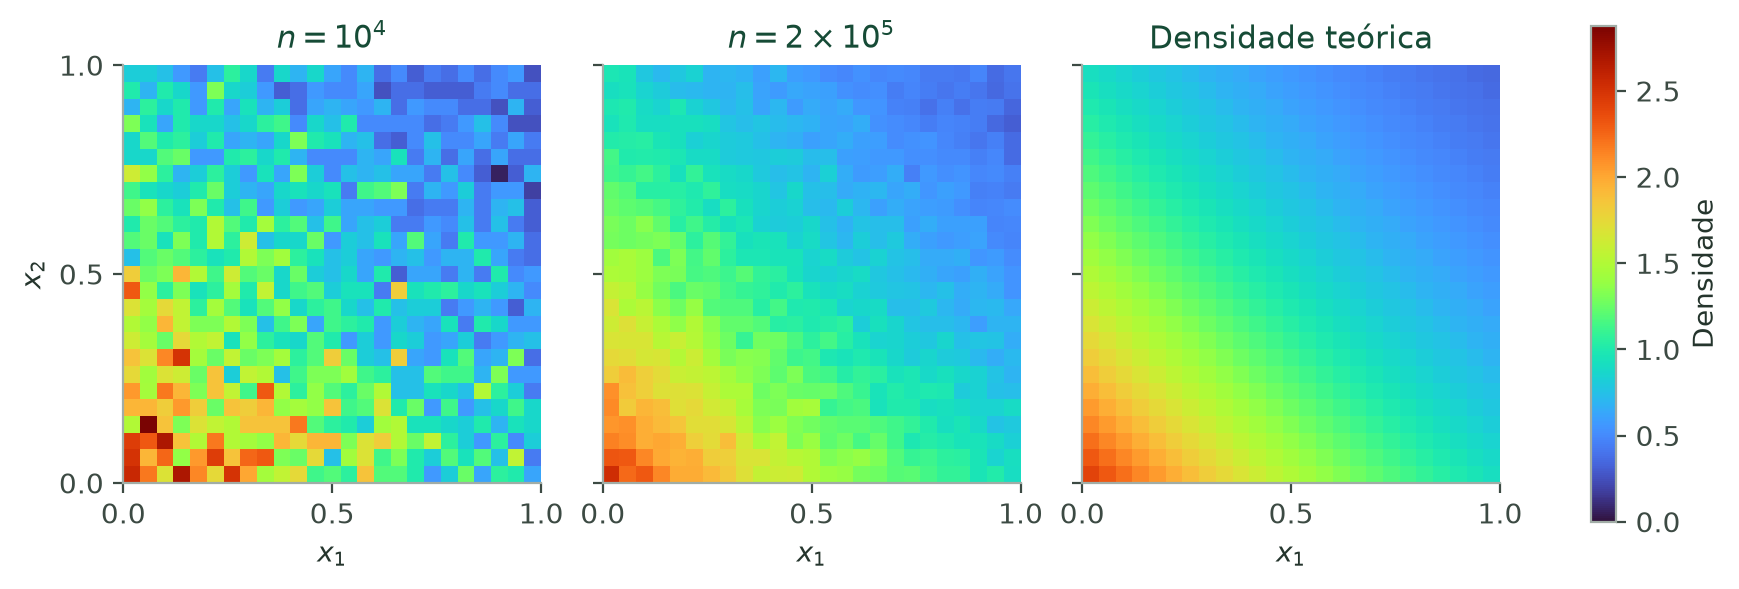

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(8.6, 3.3), sharex=True, sharey=True,
                         layout="constrained")
paineis = [*histogramas_rejeicao, densidade_teorica_rejeicao]
titulos = (r"$n=10^4$", r"$n=2\times10^5$", "Densidade teórica")
limite_cor = max(painel.max() for painel in paineis)
for eixo, painel, titulo in zip(eixos, paineis, titulos):
    mapa = eixo.pcolormesh(bins_rejeicao, bins_rejeicao, painel.T,
                          cmap="turbo", vmin=0, vmax=limite_cor)
    eixo.set(title=titulo, xlabel="$x_1$", aspect="equal")
    eixo.set_xticks([0, 0.5, 1])
    eixo.set_yticks([0, 0.5, 1])
eixos[0].set_ylabel("$x_2$")
fig.colorbar(mapa, ax=eixos, shrink=0.77, label="Densidade")
mostrar_figura(fig, "rejeicao.png")

## Exercício 3 — Regra da cadeia

Gere $10^5$ pontos uniformes no disco unitário. Sorteie primeiro $X_1$, cuja marginal é $p_{X_1}(x_1)=2\sqrt{1-x_1^2}/\pi$ em $[-1,1]$. Depois sorteie $X_2$ uniformemente no segmento vertical definido por $X_1$. Use que $(X_1+1)/2$ tem distribuição $\mathrm{Beta}(3/2,3/2)$.

In [6]:
rng_cadeia = np.random.default_rng(8315)
n_cadeia = 100_000
x_1 = 2 * rng_cadeia.beta(1.5, 1.5, n_cadeia) - 1
semi_corda = np.sqrt(1 - x_1**2)
x_2 = (2 * rng_cadeia.random(n_cadeia) - 1) * semi_corda
pontos_cadeia = np.column_stack((x_1, x_2))
raio_quadrado = x_1**2 + x_2**2

print(f"{'componente':>10} {'média':>12} {'variância':>12}")
for k, (media, variancia) in enumerate(
    zip(pontos_cadeia.mean(axis=0), pontos_cadeia.var(axis=0)), start=1
):
    print(f"{k:10d} {media:12.6f} {variancia:12.6f}")
print(f"E[R²] amostral = {raio_quadrado.mean():.6f}")
print(f"P(R ≤ 0,5) amostral = {np.mean(raio_quadrado <= 0.25):.4%}")
print(f"Pontos fora do disco = {np.count_nonzero(raio_quadrado > 1)}")

componente        média    variância
         1     0.002033     0.251146
         2     0.000145     0.250134
E[R²] amostral = 0.501283
P(R ≤ 0,5) amostral = 24.8580%
Pontos fora do disco = 0


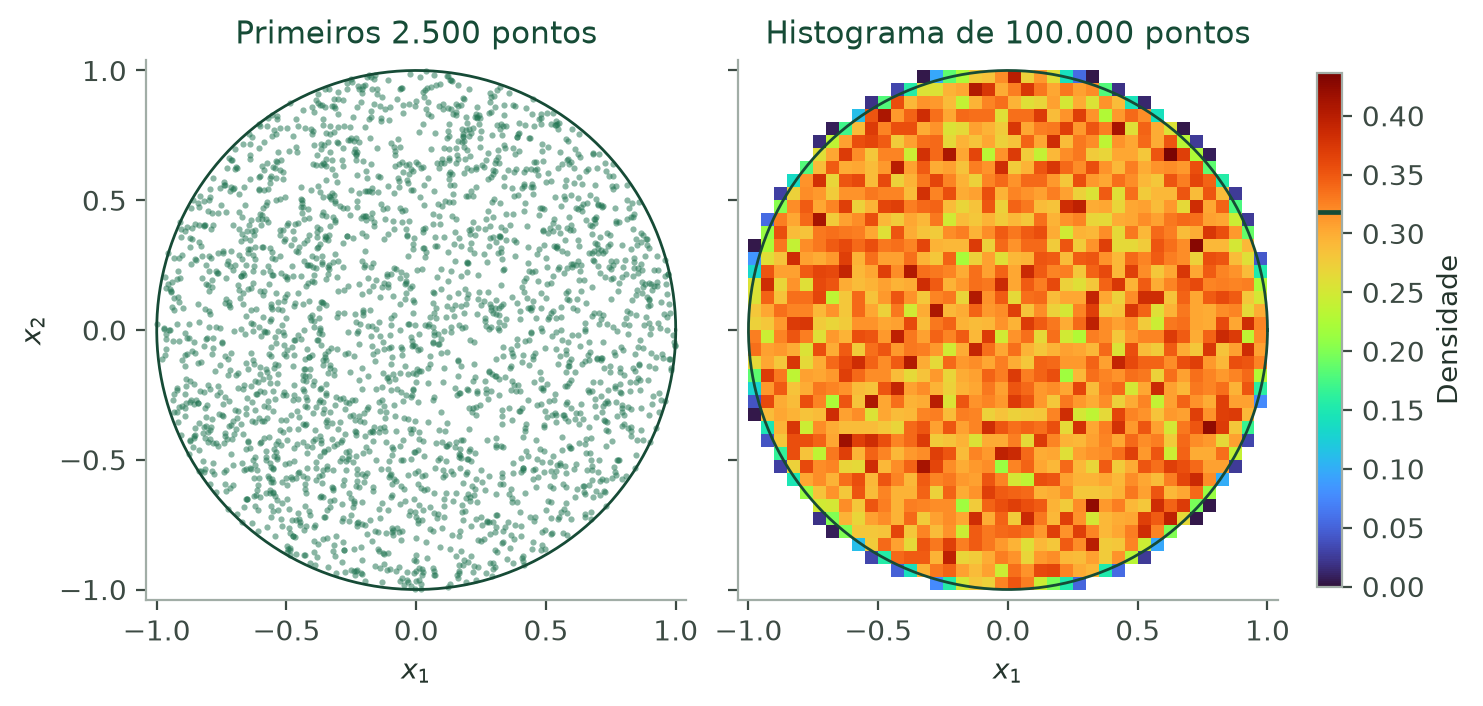

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(7.3, 3.6), sharex=True, sharey=True,
                         layout="constrained")
eixos[0].scatter(x_1[:2_500], x_2[:2_500], s=5, color=verde, alpha=0.52,
                 linewidths=0)
bins_cadeia = np.linspace(-1, 1, 41)
hist_cadeia, _, _ = np.histogram2d(x_1, x_2, bins=bins_cadeia, density=True)
mapa = eixos[1].pcolormesh(bins_cadeia, bins_cadeia,
                           np.ma.masked_equal(hist_cadeia.T, 0),
                           cmap="turbo", vmin=0)
angulo = np.linspace(0, 2 * np.pi, 360)
for eixo, titulo in zip(eixos, ("Primeiros 2.500 pontos", "Histograma de 100.000 pontos")):
    eixo.plot(np.cos(angulo), np.sin(angulo), color=verde_escuro, linewidth=1.0)
    eixo.set(title=titulo, xlabel="$x_1$", aspect="equal",
             xlim=(-1.04, 1.04), ylim=(-1.04, 1.04))
    eixo.set_xticks([-1, -0.5, 0, 0.5, 1])
    eixo.set_yticks([-1, -0.5, 0, 0.5, 1])
eixos[0].set_ylabel("$x_2$")
barra = fig.colorbar(mapa, ax=eixos[1], shrink=0.8, label="Densidade",
                    format=StrMethodFormatter("{x:.2f}"))
barra.ax.axhline(1 / np.pi, color=verde_escuro, linewidth=1.7)
mostrar_figura(fig, "regra_da_cadeia.png")

## Exercício 4 — Médias amostrais

Para cada tamanho $m \in \{10^2,10^3,10^4,10^5\}$, calcule 1.000 médias de amostras de um vetor com duas componentes independentes. Repita para componentes $\mathcal{N}(0,1)$ e $\mathrm{Cauchy}(0,1)$. Compare a dispersão das médias à medida que $m$ aumenta.

In [8]:
def medias_em_blocos(gerar, m, repeticoes):
    medias = np.empty((repeticoes, 2))
    bloco = 20
    for inicio in range(0, repeticoes, bloco):
        fim = min(inicio + bloco, repeticoes)
        medias[inicio:fim] = gerar(size=(fim - inicio, m, 2)).mean(axis=1)
    return medias


rng_gaussiana = np.random.default_rng(1209)
rng_cauchy = np.random.default_rng(1211)
tamanhos_medias = (100, 1_000, 10_000, 100_000)
repeticoes = 1_000
medias_gaussianas = {}
medias_cauchy = {}
amplitude_normal = 2 * NormalDist().inv_cdf(0.75)

print("AIQ = amplitude interquartil")
print(f"{'m':>8} {'Gauss X1':>10} {'Gauss X2':>10} {'Gauss teo.':>11} "
      f"{'Cauchy X1':>10} {'Cauchy X2':>10} {'Fora de [-5,5]²':>16}")
for m in tamanhos_medias:
    gauss = medias_em_blocos(rng_gaussiana.standard_normal, m, repeticoes)
    cauchy = medias_em_blocos(rng_cauchy.standard_cauchy, m, repeticoes)
    medias_gaussianas[m] = gauss
    medias_cauchy[m] = cauchy
    aiq_gauss = np.diff(np.quantile(gauss, [0.25, 0.75], axis=0), axis=0)[0]
    aiq_cauchy = np.diff(np.quantile(cauchy, [0.25, 0.75], axis=0), axis=0)[0]
    fora_cauchy = np.count_nonzero(np.any(np.abs(cauchy) > 5, axis=1))
    print(f"{m:8d} {aiq_gauss[0]:10.6f} {aiq_gauss[1]:10.6f} "
          f"{amplitude_normal / np.sqrt(m):11.6f} {aiq_cauchy[0]:10.6f} "
          f"{aiq_cauchy[1]:10.6f} {fora_cauchy:16d}")
print(f"AIQ teórica de Cauchy = 2; fração teórica fora do quadro = "
      f"{1 - (2 * np.arctan(5) / np.pi)**2:.4%}")

AIQ = amplitude interquartil
       m   Gauss X1   Gauss X2  Gauss teo.  Cauchy X1  Cauchy X2  Fora de [-5,5]²
     100   0.132164   0.132327    0.134898   2.073334   1.997751              237
    1000   0.039562   0.041851    0.042658   1.957300   1.973949              227


   10000   0.013792   0.013516    0.013490   1.821610   2.039102              253


  100000   0.004252   0.004124    0.004266   2.048736   1.874315              232
AIQ teórica de Cauchy = 2; fração teórica fora do quadro = 23.5540%


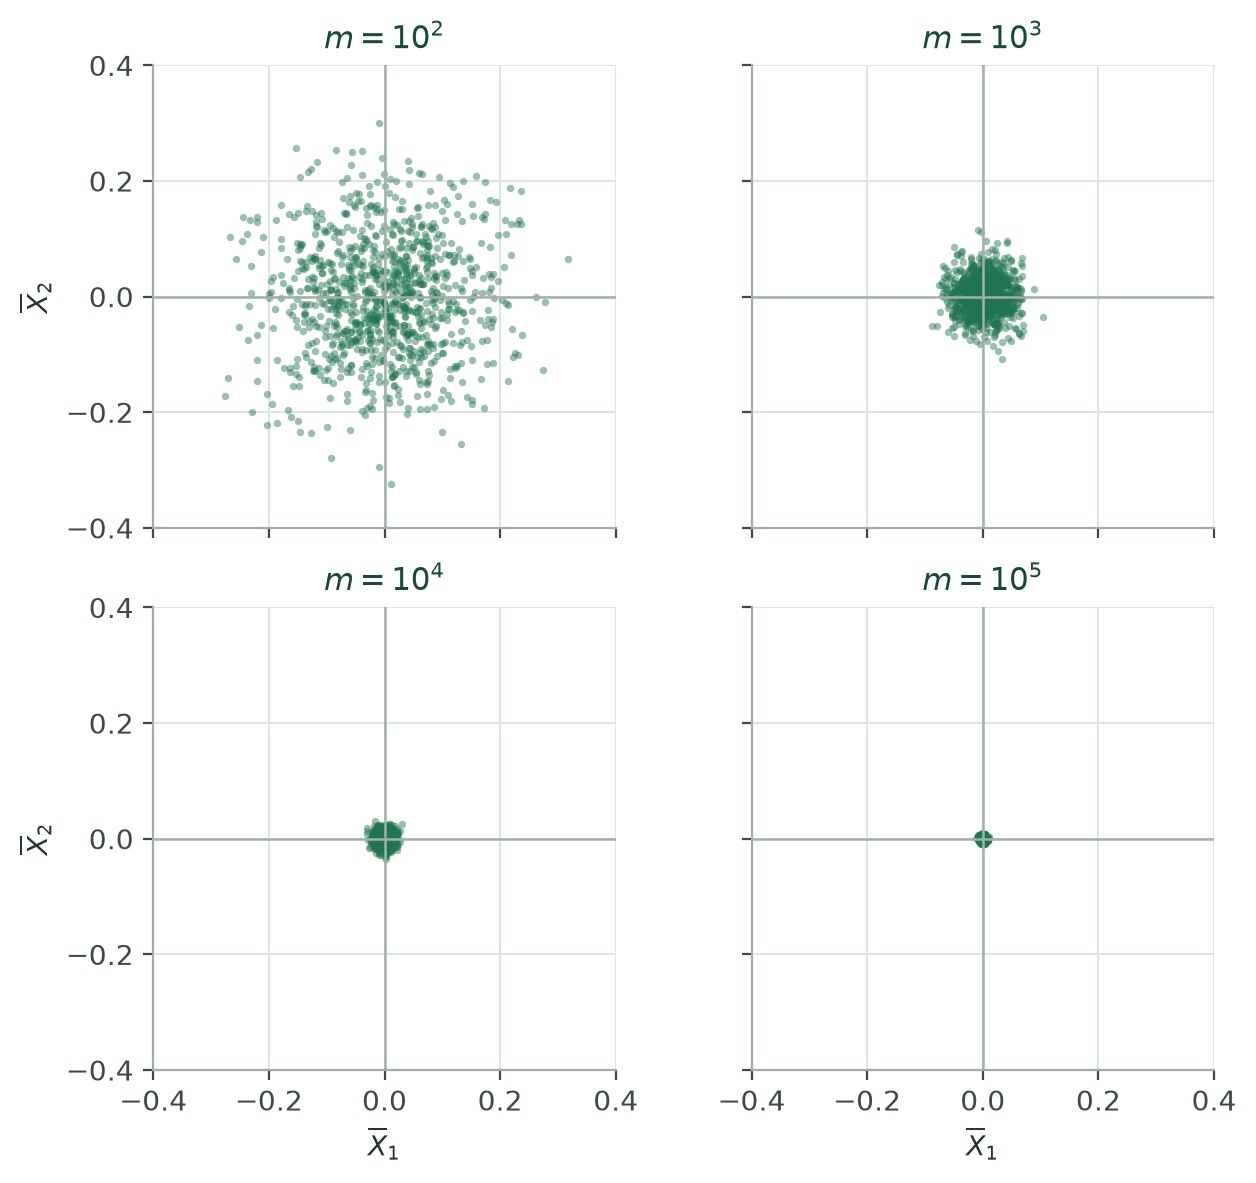

In [9]:
def painel_medias(medias_por_tamanho, limite, marcas, cor):
    fig, eixos = plt.subplots(2, 2, figsize=(6.4, 5.8), sharex=True, sharey=True,
                             layout="constrained")
    for eixo, (m, medias) in zip(eixos.flat, medias_por_tamanho.items()):
        visiveis = np.all(np.abs(medias) <= limite, axis=1)
        eixo.axhline(0, color="#A2B1A7", linewidth=0.9)
        eixo.axvline(0, color="#A2B1A7", linewidth=0.9)
        eixo.grid()
        eixo.scatter(*medias[visiveis].T, s=7, color=cor, alpha=0.46,
                     linewidths=0)
        expoente = len(str(m)) - 1
        titulo = rf"$m=10^{expoente}$"
        fora = np.count_nonzero(~visiveis)
        if fora:
            titulo += f"  ({fora} fora)"
        eixo.set(title=titulo, aspect="equal",
                 xlim=(-limite, limite), ylim=(-limite, limite))
        eixo.set_xticks(marcas)
        eixo.set_yticks(marcas)
    for eixo in eixos[-1]:
        eixo.set_xlabel(r"$\overline{X}_1$")
    for eixo in eixos[:, 0]:
        eixo.set_ylabel(r"$\overline{X}_2$")
    return fig


fig = painel_medias(medias_gaussianas, 0.4, np.linspace(-0.4, 0.4, 5), verde)
mostrar_figura(fig, "medias_gaussianas.png")

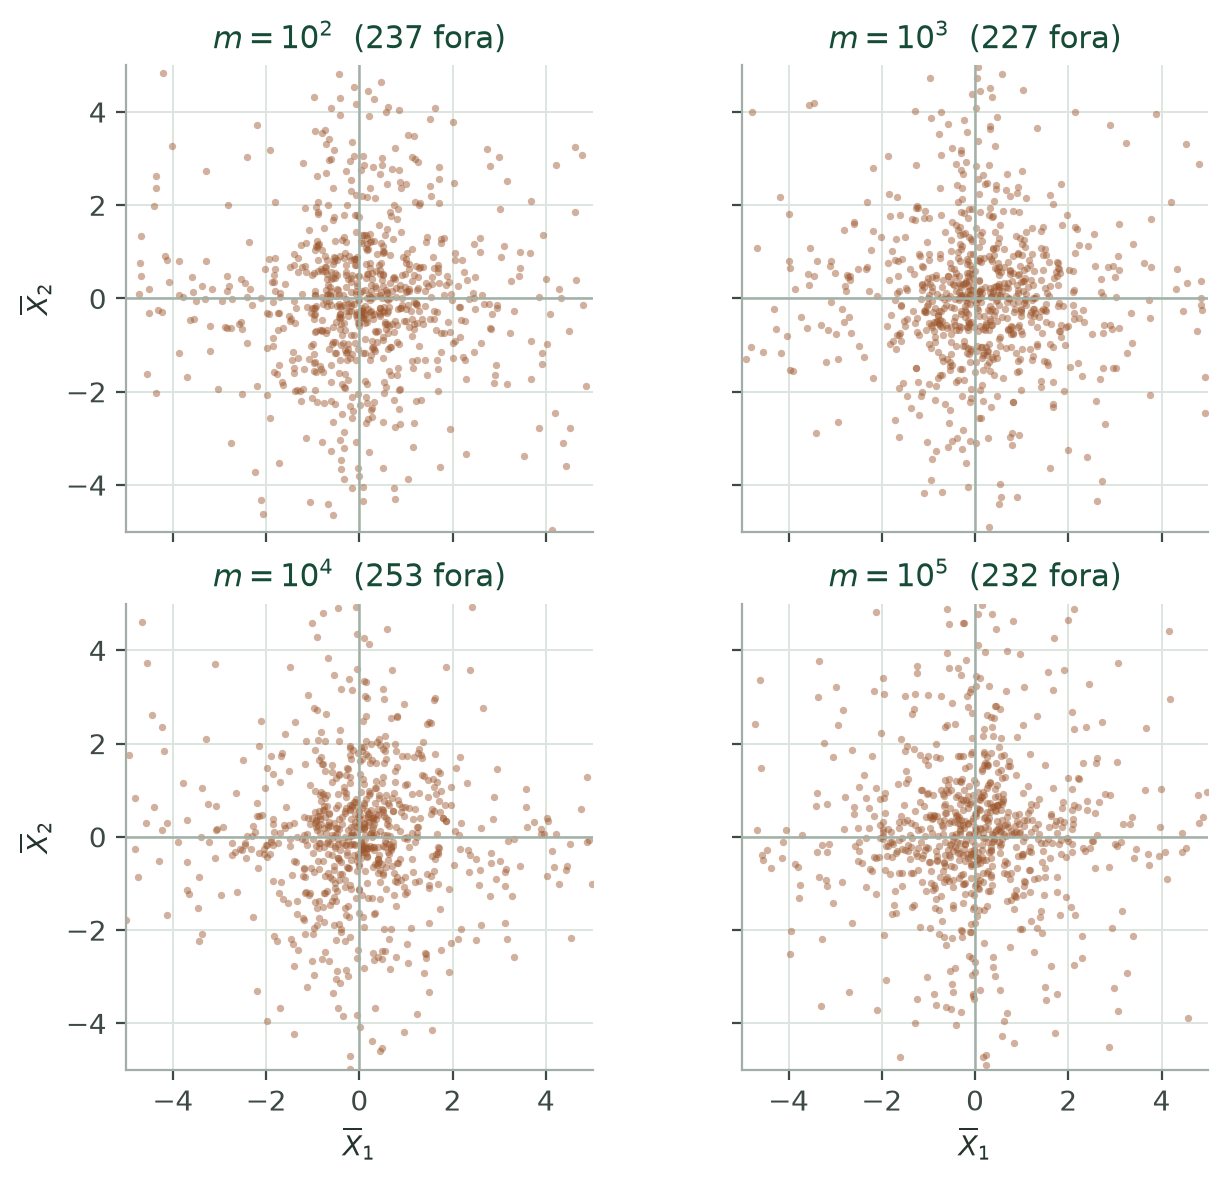

In [10]:
fig = painel_medias(medias_cauchy, 5, [-4, -2, 0, 2, 4], "#9B552B")
mostrar_figura(fig, "medias_cauchy.png")